In [ ]:
import pandas as pd
df = pd.read_csv("/SampleSuperstore.csv")
print(df.shape)              # note the row count
df.info()
print(df.isnull().sum())
print(df.duplicated().sum()) # note duplicates
df = df.drop_duplicates()
print(df.shape)              # rows after cleaning
df["Profit Margin %"] = df["Profit"] / df["Sales"] * 100

(9994, 13)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 13 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Ship Mode     9994 non-null   object 
 1   Segment       9994 non-null   object 
 2   Country       9994 non-null   object 
 3   City          9994 non-null   object 
 4   State         9994 non-null   object 
 5   Postal Code   9994 non-null   int64  
 6   Region        9994 non-null   object 
 7   Category      9994 non-null   object 
 8   Sub-Category  9994 non-null   object 
 9   Sales         9994 non-null   float64
 10  Quantity      9994 non-null   int64  
 11  Discount      9994 non-null   float64
 12  Profit        9994 non-null   float64
dtypes: float64(3), int64(2), object(8)
memory usage: 1015.1+ KB
Ship Mode       0
Segment         0
Country         0
City            0
State           0
Postal Code     0
Region          0
Category        0
Sub-Category    0
Sales     

In [ ]:
import sqlite3
conn = sqlite3.connect(":memory:")
df.to_sql("superstore", conn, index=False)
def q(sql): return pd.read_sql(sql, conn)

In [ ]:
# 1. Profit by category
q("SELECT Category, ROUND(SUM(Sales),0) sales, ROUND(SUM(Profit),0) profit FROM superstore GROUP BY Category")

,Category,sales,profit
0,Furniture,741306.0,18422.0
1,Office Supplies,718735.0,122365.0
2,Technology,836154.0,145455.0


In [ ]:
# 2. Worst sub-categories
q("SELECT `Sub-Category`, ROUND(SUM(Profit),0) profit FROM superstore GROUP BY 1 ORDER BY profit LIMIT 5")

,Sub-Category,profit
0,Tables,-17725.0
1,Bookcases,-3473.0
2,Supplies,-1189.0
3,Fasteners,950.0
4,Machines,3385.0


In [ ]:
q("""SELECT CASE WHEN Discount=0 THEN '0%' WHEN Discount<=0.2 THEN '1-20%'
     WHEN Discount<=0.4 THEN '21-40%' ELSE '40%+' END AS discount_level,
     ROUND(AVG(Profit),1) avg_profit, COUNT(*) orders
     FROM superstore GROUP BY 1""")

,discount_level,avg_profit,orders
0,0%,67.0,4787
1,1-20%,26.5,3799
2,21-40%,-78.0,459
3,40%+,-106.8,932


In [ ]:
q("""SELECT `Sub-Category`, ROUND(AVG(Discount)*100,1) avg_discount_pct, ROUND(SUM(Profit),0) profit
     FROM superstore GROUP BY 1 ORDER BY avg_discount_pct DESC LIMIT 5""")

,Sub-Category,avg_discount_pct,profit
0,Binders,37.2,30228.0
1,Machines,30.6,3385.0
2,Tables,26.1,-17725.0
3,Bookcases,21.1,-3473.0
4,Chairs,17.0,26567.0


In [ ]:
q("SELECT Region, ROUND(SUM(Profit),0) profit FROM superstore GROUP BY Region ORDER BY profit")

,Region,profit
0,Central,39656.0
1,South,46749.0
2,East,91506.0
3,West,108330.0


In [ ]:
q("""SELECT Region, ROUND(SUM(Sales),0) sales, ROUND(SUM(Profit)*100.0/SUM(Sales),1) margin_pct,
     ROUND(AVG(Discount)*100,1) avg_discount_pct
     FROM superstore GROUP BY Region ORDER BY margin_pct""")

,Region,sales,margin_pct,avg_discount_pct
0,Central,500783.0,7.9,24.0
1,South,391722.0,11.9,14.7
2,East,678435.0,13.5,14.5
3,West,725256.0,14.9,11.0


In [ ]:
q("""SELECT Category, `Sub-Category`, ROUND(SUM(Profit),0) profit,
     RANK() OVER (PARTITION BY Category ORDER BY SUM(Profit) DESC) rnk
     FROM superstore GROUP BY Category, `Sub-Category`""")

,Category,Sub-Category,profit,rnk
0,Furniture,Chairs,26567.0,1
1,Furniture,Furnishings,13053.0,2
2,Furniture,Bookcases,-3473.0,3
3,Furniture,Tables,-17725.0,4
4,Office Supplies,Paper,33944.0,1
5,Office Supplies,Binders,30228.0,2
6,Office Supplies,Storage,21279.0,3
7,Office Supplies,Appliances,18138.0,4
8,Office Supplies,Envelopes,6964.0,5
9,Office Supplies,Art,6525.0,6


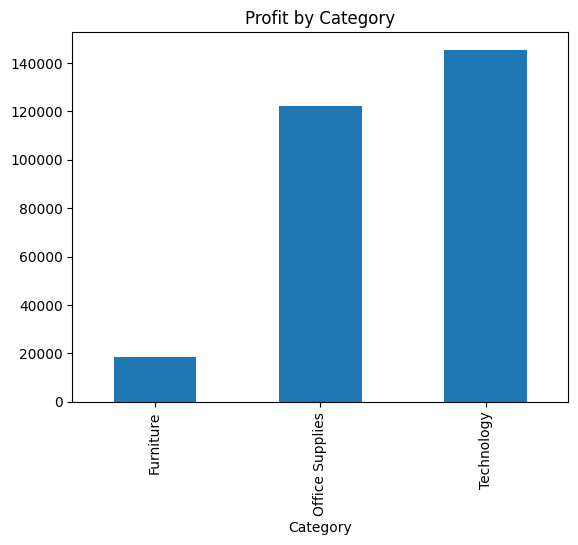

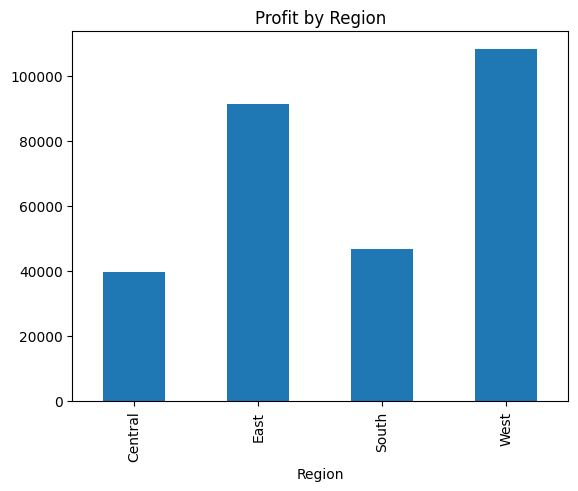

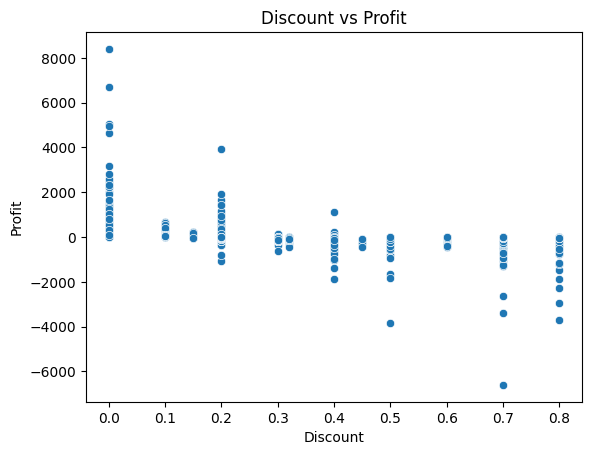

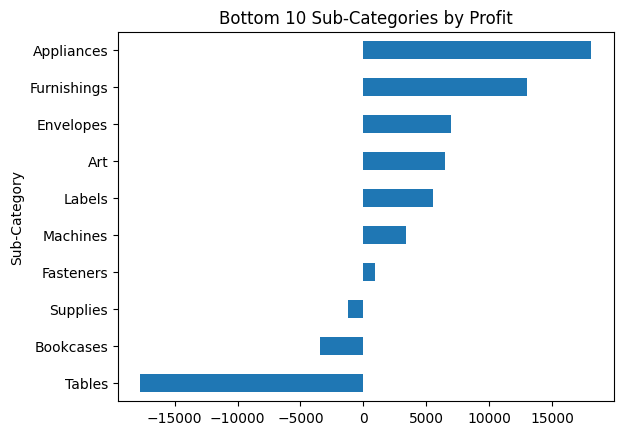

In [ ]:
import matplotlib.pyplot as plt, seaborn as sns

df.groupby("Category")["Profit"].sum().plot(kind="bar", title="Profit by Category"); plt.show()
df.groupby("Region")["Profit"].sum().plot(kind="bar", title="Profit by Region"); plt.show()
sns.scatterplot(data=df, x="Discount", y="Profit"); plt.title("Discount vs Profit"); plt.show()
df.groupby("Sub-Category")["Profit"].sum().sort_values().head(10).plot(kind="barh", title="Bottom 10 Sub-Categories by Profit"); plt.show()